In [2]:
from anemone.transforms import *
from anemone import constants as c
from anemone.physics import refl_transverse_electric as rte
from anemone.physics import freespace_u0

In [54]:
class DipoleTxDipoleRx_LaplaceHankel:
    def __init__(self, seperation, times):
        self.dx = torch.tensor(seperation)
        self.times = times
        self.tmin = torch.tensor(self.times.min(), dtype=torch.float64)
        self.tmax = torch.tensor(self.times.max(), dtype=torch.float64)

    def forward(self):
        def wavelength_integrand(wavelength):
            lmb = wavelength[None, :, None]
            def s_integrand(s):
                omega = -1j*s[None, None, :]
                u0 = freespace_u0(omega, lmb)
                cRTE = rte(self.sigma, self.thick, omega, lmb)
                return (1+cRTE)*lmb**3 / u0
            ift = invLaplace(s_integrand, n_coefficients=8)
            return ift(self.times).squeeze() / c.fourpi
        hkl = Hankel(wavelength_integrand, 0, range=(self.dx*0.99, self.dx*1.01), tolerance=1e-4)
        return hkl(self.dx).squeeze().real

    def __call__(self, sigma, thick):    
        self.sigma = (sigma+0j)[:, None,None]
        self.thick = (thick+0j)[:, None,None]
        return self.forward()

In [55]:
class DipoleTxDipoleRx_HankelLaplace:
    def __init__(self, seperation, times):
        self.dx = torch.tensor(seperation)
        self.times = times
        self.tmin = torch.tensor(self.times.min(), dtype=torch.float64)
        self.tmax = torch.tensor(self.times.max(), dtype=torch.float64)

    def forward(self):
        def s_integrand(s):
            omega = -1j*s[None, :, None]
            def wavelength_integrand(wavelength):
                lmb = wavelength[None, None, :]
                u0 = freespace_u0(omega, lmb)
                cRTE = rte(self.sigma, self.thick, omega, lmb)
                return (1+cRTE)*lmb**3 / u0
            hkl = Hankel(wavelength_integrand, 0, range=(self.dx*0.99, self.dx*1.01), tolerance=1e-4)
            return hkl(self.dx).squeeze()
        ift = invLaplace(s_integrand, n_coefficients=8)
        return ift(self.times).real / c.fourpi

    def __call__(self, sigma, thick):    
        self.sigma = (sigma+0j)[:, None,None]
        self.thick = (thick+0j)[:, None,None]
        return self.forward()

In [56]:
import torch
t = torch.logspace(-7, -1, 51, dtype=torch.float64)
sigma = torch.tensor([1e-2, 1e-2])
thick = torch.tensor([40])

dhdt_lim = (1./20)*(sigma[0]*c.mu0/c.pi)**(3/2) * t**(-5/2)

fwrLH = DipoleTxDipoleRx_LaplaceHankel(100, t)
dhdt_LH = fwrLH(sigma, thick)

fwrHL = DipoleTxDipoleRx_HankelLaplace(100, t)
dhdt_HL = fwrHL(sigma, thick)

C:\Users\au646858\AppData\Local\Temp\ipykernel_17292\2855532952.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.tmin = torch.tensor(self.times.min(), dtype=torch.float64)
C:\Users\au646858\AppData\Local\Temp\ipykernel_17292\2855532952.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.tmax = torch.tensor(self.times.max(), dtype=torch.float64)


In [57]:
%%timeit
dhdt_LH = fwrLH(sigma, thick)


60.1 ms ± 1.32 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [58]:
%%timeit
dhdt_HL = fwrHL(sigma, thick)

286 ms ± 9.82 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


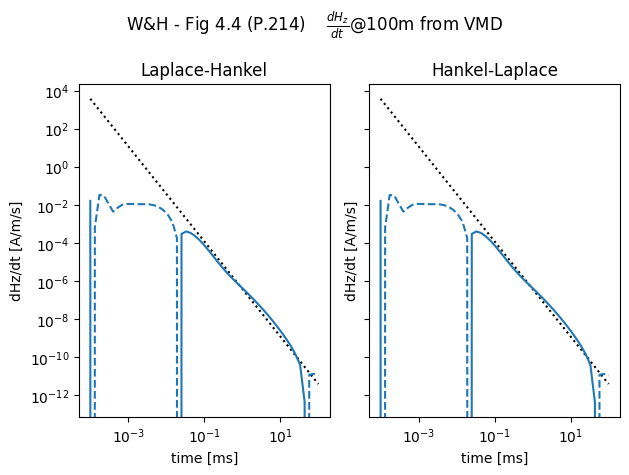

In [53]:
import matplotlib.pyplot as plt
import numpy as np

fig,axs = plt.subplots(1,2, sharex=True, sharey=True)

axs[0].loglog(fwrLH.times.numpy()*1000, dhdt_lim.numpy(), 'k:')
axs[1].loglog(fwrLH.times.numpy()*1000, dhdt_lim.numpy(), 'k:')

axs[0].loglog(fwrLH.times.numpy()*1000, dhdt_LH.numpy())
axs[0].loglog(fwrLH.times.numpy()*1000, -dhdt_LH.numpy(), 'C0--')
axs[1].loglog(fwrHL.times.numpy()*1000, dhdt_HL.numpy())
axs[1].loglog(fwrHL.times.numpy()*1000, -dhdt_HL.numpy(), 'C0--')

for ax in axs:
    ax.set_xlabel('time [ms]')
    ax.set_ylabel('dHz/dt [A/m/s]')
fig.suptitle('W&H - Fig 4.4 (P.214) \t $\\frac{dH_z}{dt}$@100m from VMD')
axs[0].set_title('Laplace-Hankel')
axs[1].set_title('Hankel-Laplace')
plt.tight_layout()